## Utilizzo di rete pre addestrate sul dataset ImageNet per classificare immagini

Import librerie di utility

In [11]:
%reset -f
import numpy as np
import matplotlib.pyplot as plt

Carico immagine

In [12]:
# Caricamento dell’immagine
import skimage.io as io
from skimage.transform import resize

img = np.float32(io.imread('mare.jpg'))
img = resize(img, (299, 299), order=1)

Carico la rete pre addestrata

In [13]:
# Caricamento della rete
from keras.applications.xception import Xception

model = Xception(weights='imagenet')

Preparo i dati da mandare in input (4 dimensioni)

In [14]:
# Preparazione dei dati
from keras.applications.xception import preprocess_input

x = np.reshape(img, (1,img.shape[0],img.shape[1],img.shape[2]))
x = preprocess_input(np.copy(x))

avvio la predizione

In [15]:
# Predizione
preds = model.predict(x)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


Visualizzazione del risultato

N.B. La funzione decode_predictions() è specifica per modelli pre-addestrati in Keras (come Xception, ResNet, ecc.).

Converte gli output numerici del modello in etichette testuali comprensibili (es.: "golden retriever") e probabilità associate.

Il parametro top=5 indica di restituire solo le prime 5 classi più probabili.

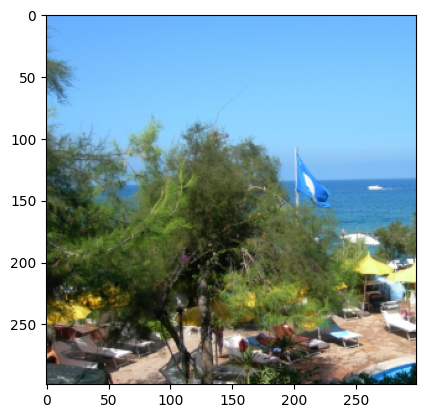

('n09428293', 'seashore', np.float32(0.58207816))
('n09332890', 'lakeside', np.float32(0.15952638))
('n09399592', 'promontory', np.float32(0.06185624))
('n09421951', 'sandbar', np.float32(0.016940627))
('n02814860', 'beacon', np.float32(0.010221266))


In [16]:
# Visualizzazione del risultato
from keras.applications.xception import decode_predictions

plt.figure(); plt.imshow(img/255); plt.show();
preds_d = decode_predictions(preds, top=5)[0]
for p in preds_d:
  print(p)